## Module 3: Computational Drug Discovery Project 



## Disease Background

- Obesity is a medical condition defined by a BMI of 30 or higher․ Approximately 40․3% of U․S․ adults reported being obese in 2021-2023‚ according to CDC data․ Health complications related to obesity include type 2 diabetes‚ heart disease‚ and high blood pressure․ [CDC Data](https://www.cdc.gov/nchs/products/databriefs/db508.htm)

- Obesity treatments include behavioral therapy and weight-loss drugs and surgery․ New weight-loss drugs include Wegovy (semaglutide) and Zepbound (tirzepatide)․ Weight-loss drugs work by affecting hormone pathways involved in appetite control․ [Obesity Treatments](https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment) | [Weight-Loss Medications](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity)

- Current therapies have limitations․ Medications may have side effects and need to be used for many years‚ among other limitations‚ and may not be covered or fully reimbursed by most insurance and other payers․ Ways to overcome barriers to therapy include the development of more convenient and inexpensive treatments․ [Medication Limitations](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity)

- Our project focuses on Cavalitide‚ a proposed GLP1 receptor agonist․ We are studying Cavalitide receptor binding and concentration over time to gain knowledge that could help make Cavalitide a useful alternative to other weight-loss medications․ (Module 3 Project Description)


## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Load Cavalitide experimental data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)

print("Data loaded successfully!")
print(data[:5])


Data loaded successfully!
[[0.001      0.09528827]
 [0.00284804 0.10622711]
 [0.00811131 0.17861281]
 [0.0231013  0.27693139]
 [0.06579332 0.46054832]]


Cavalitide Kd: 0.07696604138418876 nM


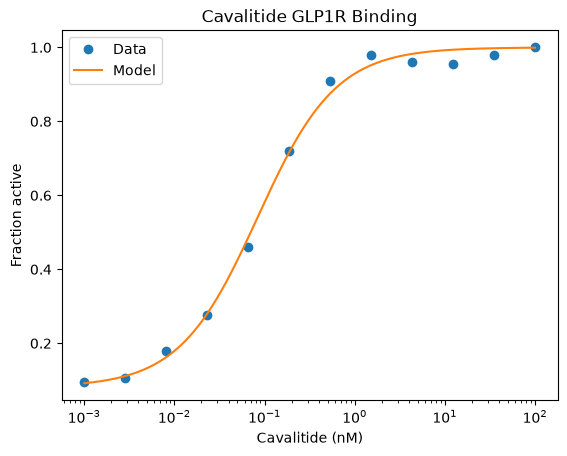

In [10]:

# Cavalitide data
L2 = data[:, 0]
y = data[:, 1]

# GLP1 values
L1 = 0.015
Kd1 = 0.17

# Receptor activation
def Fact(L2, Kd2):
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Finding Kd for Cavalitide
popt, pcov = curve_fit(Fact, L2, y, p0=[0.1])
Kd2 = popt[0]

print("Cavalitide Kd:", Kd2, "nM")

# Plot
x = np.logspace(-3, 2, 500)

plt.figure()
plt.semilogx(L2, y, 'o', label="Data")
plt.semilogx(x, Fact(x, Kd2), label="Model")

plt.xlabel("Cavalitide (nM)")
plt.ylabel("Fraction active")
plt.title("Cavalitide GLP1R Binding")
plt.legend()
plt.show()


### Task 1 Interpretation

The Kd value for Cavalitide is 0․077 nM‚ and the Kd value for semaglutide is 0․38 nM․ Cavalitide has a lower Kd value and may have increased receptor binding and activation of GLP1R at lower concentrations․ Other factors‚ in addition to receptor binding and activation‚ such as absorption and half-life‚ should be taken into account when comparing potential drugs․

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

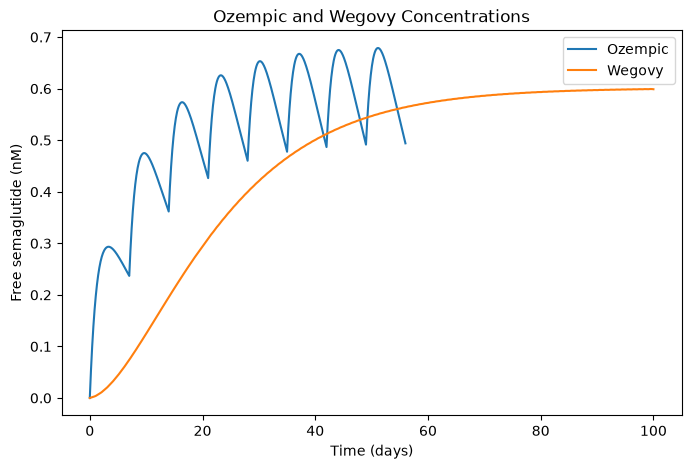

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Values from semaglutidePK.py
ke = 0.0039
V = 10.8
MW = 4113.6
Ffree = 0.01

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc
    return [dAsc, dCc]

def simulate(ka, D, Favailable, interval, n_doses):
    y = [0, 0]
    times = []
    concentrations = []

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval

        sol = solve_ivp(
            ODEfunc, [t0, t0 + interval], y,
            args=(ka,),
            t_eval=np.linspace(t0, t0 + interval, 100)
        )

        times.extend(sol.t)
        concentrations.extend(sol.y[1])
        y = sol.y[:, -1].copy()

    times = np.array(times)
    concentrations = np.array(concentrations)

    CnM = concentrations * 1e6 / MW
    return times, Ffree * CnM

# Ozempic
t1, c1 = simulate(0.029, 2.0, 0.89, 168, 8)

# Wegovy
t2, c2 = simulate(0.0029, 25, 0.01, 24, 100)

plt.figure(figsize=(8, 5))
plt.plot(t1/24, c1, label="Ozempic")
plt.plot(t2/24, c2, label="Wegovy")
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide (nM)")
plt.title("Ozempic and Wegovy Concentrations")
plt.legend()
plt.show()


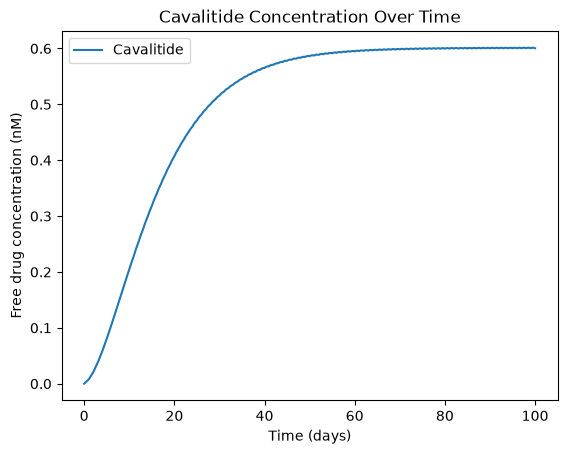

Cavalitide concentration at day 100: 0.6003838376929711 nM


In [12]:

# Cavalitide with a faster absorption rate
t3, c3 = simulate(0.006, 25, 0.01, 24, 100)

plt.figure()
plt.plot(t3/24, c3, label="Cavalitide")
plt.xlabel("Time (days)")
plt.ylabel("Free drug concentration (nM)")
plt.title("Cavalitide Concentration Over Time")
plt.legend()
plt.show()

print("Cavalitide concentration at day 100:", c3[-1], "nM")


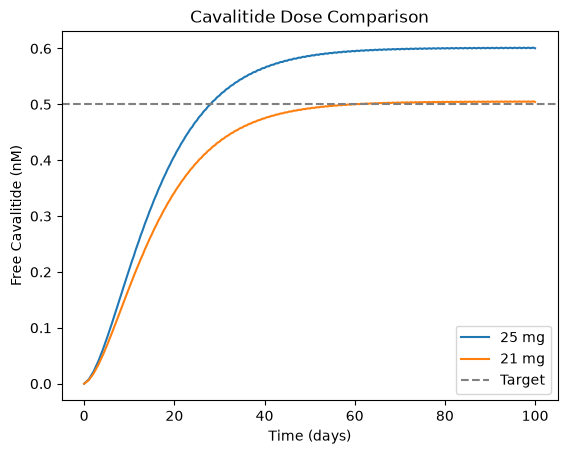

Concentration with 21 mg: 0.5043224236622356 nM


In [13]:

# Trying a lower daily dose for Cavalitide
t4, c4 = simulate(0.006, 21, 0.01, 24, 100)

plt.figure()
plt.plot(t3/24, c3, label="25 mg")
plt.plot(t4/24, c4, label="21 mg")
plt.axhline(0.5, color="gray", linestyle="--", label="Target")

plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide (nM)")
plt.title("Cavalitide Dose Comparison")
plt.legend()
plt.show()

print("Concentration with 21 mg:", c4[-1], "nM")


### Task 2 Interpretation

I reduced the daily Cavalitide dose from 25 mg to 21 mg while keeping the other parameters the same. This decreased the steady-state free blood concentration from about 0.60 nM to 0.50 nM, which is closer to our target.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions:

Our study suggests that Cavalitide is a potential alternative medication for obesity․ Task 1 results show that the Kd value for Cavalitide was 0․077 nM‚ which is lower than the Kd value for semaglutide of 0․38 nM‚ suggesting stronger GLP1R binding at lower Cavalitide doses․ Task 2 modeling of Cavalitide as an oral medication found that reducing the daily dose from 25 mg to 21 mg reduced the steady-state unbound plasma concentration from approximately 0․60 nM to 0․50 nM․ Findings from this study suggest potential uses for Cavalitide as an oral medication․ Further research is needed to evaluate the relative benefits of Cavalitide compared with oral or injectable semaglutide․

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
https://github.com/ahemdhira-arch/BME2315-Module3.git



## References

1. **CDC – Obesity and Severe Obesity Prevalence in Adults**  
   https://www.cdc.gov/nchs/products/databriefs/db508.htm

2. **NIDDK – Treatment for Overweight & Obesity**  
   https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment

3. **NIDDK – Prescription Medications to Treat Overweight & Obesity**  
   https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity

4. **UVA BME 2315 – Module 3 Project Description (Fall 2026)**  
   Course-provided document: `Module 3 project description(1).pdf`

5. **UVA BME 2315 – Receptor Binding and Pharmacokinetics Code (Fall 2026)**  
   Course-provided files: `ligand_receptor.py`, `GLP1_GLP1R.py`, `fit_semaglutide_GLP1R.py`, `semaglutidePK.py`

6. **UVA BME 2315 – Experimental Binding Data (Fall 2026)**  
   Course-provided datasets: `cavalitide_data.csv`, `semaglutide_data.csv`

7. **OpenAI – ChatGPT (2026)**  
   https://chatgpt.com/  
   Used for assistance with Python code and debugging

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*